<a href="https://colab.research.google.com/github/young-suh/ESAA_2026/blob/main/week10_note_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. 기본 라이브러리 불러오기



In [2]:
#Import basic libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.impute import SimpleImputer

2. 데이터 불러오기

In [4]:
#Load Data
test = pd.read_csv('/content/test (1).csv')
train = pd.read_csv('/content/train (1).csv')

3. 기초 데이터 탐색하기

In [5]:
#Load the test Data
test.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


In [6]:
#Load the train Data
train.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [8]:
#Percentage of missing values in the dataset
missing_percentage = (train.isnull().sum() / len(train)) * 100
print(missing_percentage)

PassengerId     0.000000
HomePlanet      2.312205
CryoSleep       2.496261
Cabin           2.289198
Destination     2.093639
Age             2.059128
VIP             2.335212
RoomService     2.082135
FoodCourt       2.105142
ShoppingMall    2.392730
Spa             2.105142
VRDeck          2.162660
Name            2.300702
Transported     0.000000
dtype: float64


In [10]:
#Percentage of missing values in the dataset
missing_percentage = (test.isnull().sum() / len(test)) * 100
print(missing_percentage)

PassengerId     0.000000
HomePlanet      2.034136
CryoSleep       2.174421
Cabin           2.338087
Destination     2.151040
Age             2.127660
VIP             2.174421
RoomService     1.917232
FoodCourt       2.478373
ShoppingMall    2.291326
Spa             2.361468
VRDeck          1.870470
Name            2.197802
dtype: float64


4. EDA

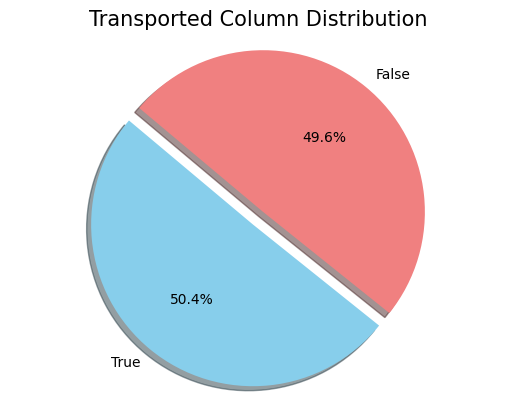

In [12]:
true_count = train['Transported'].sum()
false_count = len(train) - true_count

#Data for the pie chart
labels = ['True', 'False']
sizes = [true_count, false_count]
colors = ['skyblue', 'lightcoral']
explode = (0.1, 0)

#Create the pie chart
plt.pie(sizes, explode=explode, labels=labels, colors=colors,
        autopct='%1.1f%%', shadow=True, startangle=140)

plt.axis('equal') #Equal aspect ration ensures that pie is drawn as a circle
plt.title("Transported Column Distribution", size=15)
plt.show()

-> 전체 승객중 Transported가 True인 승객은 50.4%, False인 승객은 49.6%

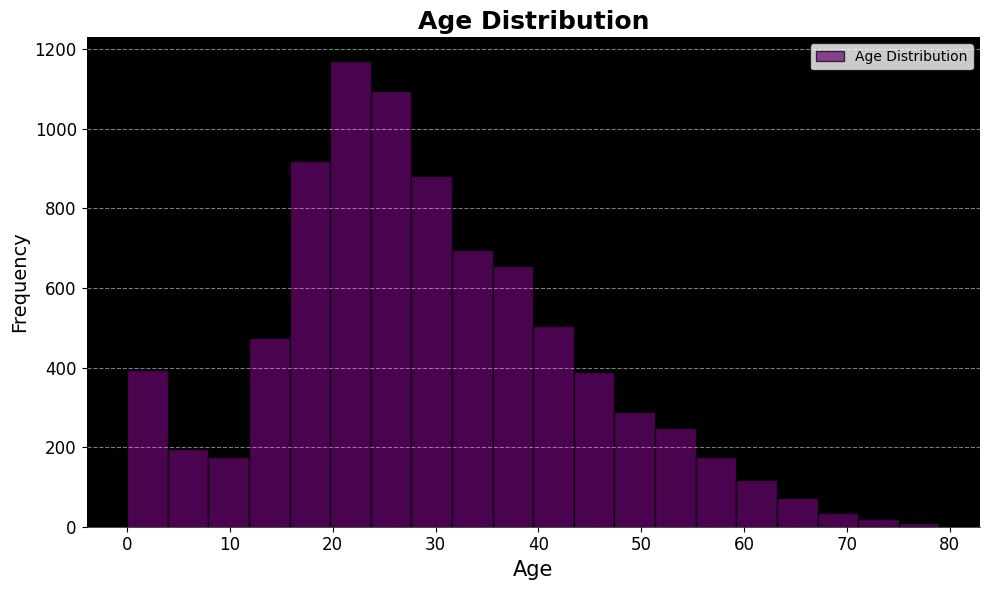

In [14]:
age_data = train['Age']

plt.figure(figsize=(10,6))
plt.hist(age_data, bins=20, edgecolor='black', color='#6A0572', alpha=0.7, label='Age Distribution')

plt.title('Age Distribution', fontsize=18, fontweight='bold', color='black')
plt.xlabel('Age', fontsize=15, color='black')
plt.ylabel('Frequency', fontsize=14, color='black')

plt.xticks(fontsize=12, color='black')
plt.yticks(fontsize=12, color='black')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.gca().set_facecolor('black')

#Remove unnevessary spins and set the layout
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(0.5)
plt.gca().spines['bottom'].set_linewidth(0.5)

#Add legend
plt.legend()
plt.tight_layout()
plt.show()

-> 전체 승객 중  20~30대의 비중이 가장 높으며, 연령이 높아질수록 승객 수가 감소하는 오른쪽으로 치우친 분포를 보임.

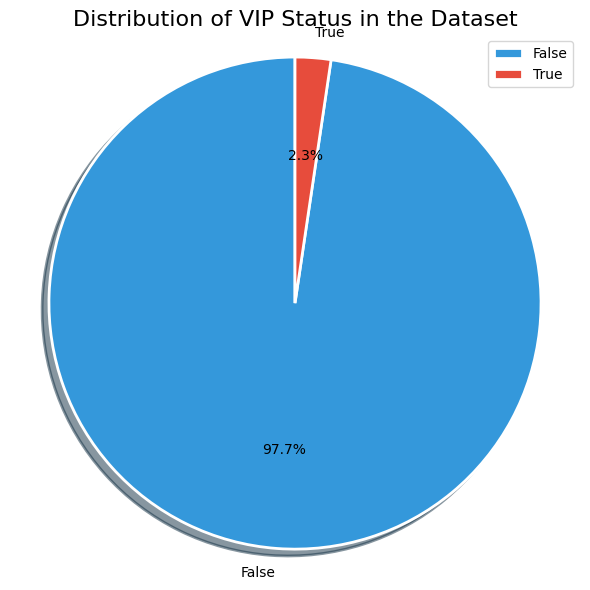

In [17]:
sex_counts = train['VIP'].value_counts()
colors = ['#3498db', '#e74c3c']

#Create the pie chart
plt.figure(figsize=(6,6))
plt.pie(sex_counts, labels=sex_counts.index, colors=colors,
        autopct='%1.1f%%', startangle=90, shadow=True, wedgeprops={'linewidth':2, 'edgecolor':'white'})

#Add a title and legend
plt.title("Distribution of VIP Status in the Dataset", fontsize=16)
plt.legend(labels=sex_counts.index, loc='upper right')

#Equal aspect ratio ensures that pie is drqwn as a circle.
plt.axis('equal')

#Show the pie chart
plt.tight_layout()
plt.show()

-> 전체 승객 중 일반 승객이 약 97.7%로 대부분을 차지하며, VIP 승객은 약 2.3%

-> VIP 여부 변수는 클래스 간 비율 차이가 매우 큰 불균형 데이터임.

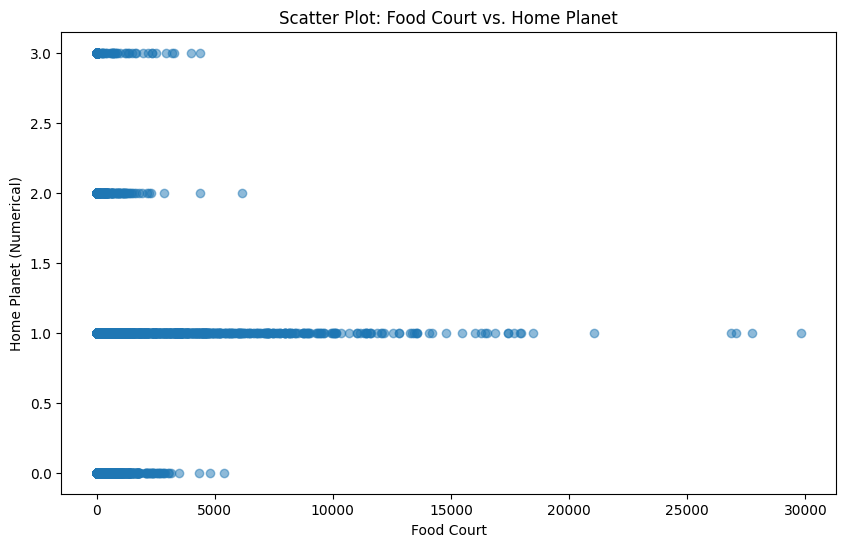

In [18]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

food_court = train['FoodCourt']
home_planet = train['HomePlanet']

label_encoder = LabelEncoder()
home_planet_numerical = label_encoder.fit_transform(home_planet)

#Create a scatter plot
plt.figure(figsize=(10,6))
plt.scatter(food_court, home_planet_numerical, alpha=0.5)

plt.xlabel('Food Court')
plt.ylabel('Home Planet (Numerical)')
plt.title('Scatter Plot: Food Court vs. Home Planet')

#Show the plot
plt.show()

-> FoodCourt 이용 금액은 대부분 낮은 구간에 집중되어 있음.

5. 데이터 전처리

In [21]:
categorical_columns = ['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt','ShoppingMall', 'Spa', 'VRDeck', 'Name']

#Create a LabelEncoder for each categorical column
label_encoders = {}
for col in categorical_columns:
  le = LabelEncoder()
  train[col] = le.fit_transform(train[col])
  label_encoders[col] = le

#Sample data with encoded categorical columns
X_categorical_encoded = train[['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']]
y = train['Transported']

#Concatenate the encoded categorical columns with other numerical columns
X_encoded = pd.concat([X_categorical_encoded, train['Age']],axis=1)

#Create an imputer with median strategy
imputer = SimpleImputer(strategy='median')

#Fit the imputer on the data and transform to fill missing values
X_imputed = imputer.fit_transform(X_encoded)

#Convert the imputed array back to a DataFrame with column names
X_imputed_df = pd.DataFrame(X_imputed, columns=X_encoded.columns)

#Assign the imputed DataFrame back to X
X = X_imputed_df

#Create a LabelEncoder for the target variable 'Transported'
label_encoder_y = LabelEncoder()
y_encoded = label_encoder_y.fit_transform(y)

#Assign the edcoded target variable back to y
y = y_encoded

In [23]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k='all')
X_new = selector.fit_transform(X,y)

#Print the selected features and their scores
selected_features = X.columns[selector.get_support()]
scores = selector.scores_[selector.get_support()]
feature_scores = list(zip(selected_features, scores))
print('Selected Features and their Scores:')
for feature, score in feature_scores:
  print(f"{feature}:{score:.2f}")

Selected Features and their Scores:
HomePlanet:102.10
CryoSleep:1702.38
Cabin:24.12
Destination:96.55
VIP:1.77
RoomService:725.48
FoodCourt:0.44
ShoppingMall:7.72
Spa:708.32
VRDeck:574.17
Name:0.60
Age:48.16


6. 모델링

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.001, random_state=15)

In [26]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()
model

RandomForestClassifier()

In [27]:
model.fit(X_train, y_train)

RandomForestClassifier()

In [28]:
model.score(X_test, y_test)

1.0

7. 예측 결과

In [30]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

#Load the test dataset
test = pd.read_csv('/content/test (1).csv')

#Apply the same LabelEncoder transformations to categorical columns
categorical_columns = ['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']

for col in categorical_columns:
  if col in label_encoders:
    le = label_encoders[col]
    #Transform test data and handle unknown categories by assigning a specific label (-1 in this case)
    test[col] = test[col].apply(lambda x: le.transform([x])[0] if x in le.classes_ else -1)

#Select the same columns as you did for training data
X_test_categorical_encoded = test[['HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name']]

#Concatenate the encoded categorical columns with other numerical columns
X_test_encoded = pd.concat([X_test_categorical_encoded, test[['Age']]], axis=1)

#Use the same imputer as in the training data
imputer = SimpleImputer(strategy='median')
X_test_imputed = imputer.fit_transform(X_test_encoded)

#Convert the imputed array back to a DataFrame with column names
X_test_imputed_df = pd.DataFrame(X_test_imputed, columns=X_test_encoded.columns)

# Now, X_test_imputed_df contains the preprocessed test data

# Make predictions on the test data using your trained model
predictions = model.predict(X_test_imputed_df)  # Replace 'model' with your trained model

# Create a submission DataFrame
submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Transported': predictions})




In [31]:
target_map = {0:'False', 1:'True'}

final_df = pd.DataFrame(submission)
final_df['Transported'] = pd.Series(predictions).map(target_map)
final_df.to_csv('submission.csv', index=False)

In [32]:
final_df

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,False
4,0023_01,True
...,...,...
4272,9266_02,True
4273,9269_01,True
4274,9271_01,True
4275,9273_01,False


<정리>
- 데이터의 특성에 따라 적절하게 시각화하는 방법에 대해 배움.
- Label Encoding을 통한 범주형 데이터 변환과 결측치 처리를 수행함.
- Feature Selection을 통해 각 변수가 에측에 갖는 통계적 관련성을 살펴봄.
- Random Forest 모델을 학습하고, 새로운 테스트 데이터에 적용하여 승객의 이동 여부를 예측함.
